# Lecture 3 : Django: Add Our First Application

# Dr. Changjiang Zhang
# CS, WKU
# Spring, 2025
 
## 1. Application

In previous tutorials, we have already learned how to create a Django project using ``D:\Django_project\django-admin startproject HelloWorld``. Now that your environment – a “project” – is set up, you’re set to start to create applications.

Each application you write in Django consists of a **Python package** that follows a certain convention. Django comes with a utility that automatically generates the basic directory structure of an app, so you can focus on writing code rather than creating directories.

**Project vs Applications:**
- An app is a Web application that does something – e.g., a Weblog system, a database of public records or a calendar application.
- A project is a collection of configuration and apps for a particular website. A project can contain multiple apps. Apps are **modules** of your project.

In the following documents, we will focus on one actual application. Let's continue the previous "HelloWorld" project and learn by an example.

## 2. WKU News App

Let's consider a WKU News application. In this application, normal users can login and get the immediate
information on today's event. 

### 2.1 Create a new application

To create your app, open the "HelloWorld" project folder and make sure you’re in the same directory as ``manage.py`` and type this command to start the app:

In [ ]:
D:\Django_project\HelloWorld> python manage.py startapp wkunews

This’ll create a directory ``wkunews``, which is laid out like this:

``HelloWorld/
    HelloWorld/
        __init__.py
        asgi.py
        settings.py
        urls.py
        views.py
        wsgi.py
    templates
        hello.html
    wkunews
        migrations
        __init__.py
        admin.py
        apps.py
        models.py
        tests.py
        views.py
    manage.py``

- ``__init__.py``: Just to make sure python handles this folder as a package.

- ``admin.py``: This file helps you make the app modifiable in the admin interface.

- ``models.py``: This is where all the application models are stored.

- ``tests.py``: This is where your unit tests are.

- ``views.py``: − This is where your application views are.

### 2.2 App Views

Let's plan our URLs and pages:

- ``'/'``: index page. The index page will be the welcome message and immediate information on the current local time.
- ``'/login'`` : user login page.

Let’s write the first view of the application. Open the file ``wkunews/views.py`` and put the following Python code in it:

In [ ]:
from django.shortcuts import render
from django.http import HttpResponse
import datetime
# Create your views here.

def index(request):
    today = datetime.datetime.now().date()
    return render(request,"hello.html",{"today":today}) # using the template we created before


To call the view, we need to map it to a URL - and for this we need a URLconf.
To create a URLconf in the wkunews directory, create a file called ``urls.py``. Your app directory should now look like:

`` wkunews
        migrations
        __init__.py
        admin.py
        apps.py
        models.py
        tests.py
        urls.py
        views.py``

In the ``wkunews/urls.py`` file include the following code:

In [ ]:
from django.urls import path

from . import views

urlpatterns = [
    path('', views.index)
]

The next step is to point the root URLconf at the wkunews.urls module. In ``HelloWorld/urls.py``, add an import for django.urls.include and insert an include() in the urlpatterns list, so you have:

In [ ]:
from django.contrib import admin
from django.urls import path,include
from . import views

urlpatterns = [
    path('admin/', admin.site.urls),
    path('',views.hello),
    path('hello/', views.hello_tmp),
    path('wkunews/',include('wkunews.urls')),
    
]


### 2.3 Registry the new app

After creating the new app, you need registry it to the project.

Find the ``sittings.py`` from the python package of your project, which is ``D:\Django_project\HelloWorld\HelloWorld\``.

Then add value ``wkunews`` to the list ``INSTALLED_APPS``, which should be look like this:

In [9]:
INSTALLED_APPS = [
    'django.contrib.admin',
    'django.contrib.auth',
    'django.contrib.contenttypes',
    'django.contrib.sessions',
    'django.contrib.messages',
    'django.contrib.staticfiles',
    'wkunews',
]

## others are build-in apps for django

Now you can start your server and type following url: ``127.0.0.1:8000/wkunews`` in your browser, you will see the following page:

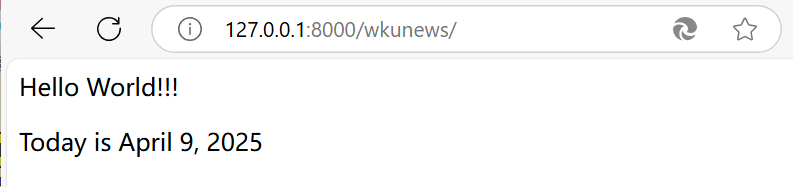

## 3. Forms in Django

Next, we show how to create a Login page in Django. The login page shows the input fieds for username and password. To simplify, the system will only allow a fixed combination of username and password, for example:
- Username: admin
- Password: admin

Note: The username and password will be checked by the Python code you are going to write, and return a
success or failed information which will also show on the login page. In real scenario, the system will connect to a database and check whether the combination of the username and password are correct, we will cover this later.

If your application wants to accept input from your visitors, you’re going to need to understand and use forms. Django provides a range of tools and libraries to help you build forms to accept input from site visitors, and then process and respond to the input.

### 3.1 HTML Forms

In HTML, a form is a collection of elements inside ``<form>...</form>`` that allow a visitor to do things like enter text, select options, manipulate objects or controls, and so on, and then send that information back to the server. Refer to data acquisition part for detailed introduction of HTML forms.

### 3.2 Django's role in forms

Handling forms is a complex business. Consider Django’s admin, where numerous items of data of several different types may need to be prepared for display in a form, rendered as HTML, edited using a convenient interface, returned to the server, validated and cleaned up, and then saved or passed on for further processing.

Django’s form functionality can simplify and automate vast portions of this work, and can also do it more securely than most programmers would be able to do in code they wrote themselves.

Django handles three distinct parts of the work involved in forms:

- preparing and restructuring data to make it ready for rendering
- creating HTML forms for the data
- receiving and processing submitted forms and data from the client


### 3.3 Django ``Form`` class

A django ``Form`` class describes a form and determines how it works and appears. Form class’s fields map to HTML form ``<input>`` elements. A form’s fields are themselves classes; they manage form data and perform validation when a form is submitted.

Suppose we want the following login form:

In [ ]:
<form action="/login" method="POST">
    <input type="text" id="username" name="username"/>
    <input type="password" id="password" name="password"/>
    <input type="submit" value="Login">
</form>

Then, create a ``forms.py`` under the wkunews folder and define the form class:

In [ ]:
from django import forms

class LoginForm(forms.Form):
    username = forms.CharField(label = 'Username', max_length=25)
    password = forms.CharField(label= 'Password', max_length=30, widget=forms.PasswordInput)

We create the Loginform, which is an instance of the ``Form`` class.
- This form just has 2 fields: username and password. That's all we need to log in a user.
- The username can be a maximum of 25 characters and the password can be a maximum of 30 characters.
- A widget is Django’s representation of an HTML input element. It is an effective way to customize the display of the form element. Whenever we specify a field on a form, Django will use a default widget that is appropriate to the type of data that is to be displayed.
- Refer to the [form field](https://docs.djangoproject.com/en/3.0/ref/forms/fields/) document for more details

Create a new template ``login.html`` for the login page:

In [ ]:
<h2>Login</h2>

<form method="post">
  {% csrf_token %}
  {{ form.as_p }}
  <input type="submit">
</form>

- ``{{ form.as_p }}``: Render Django Forms as paragraph.
- ``{% csrf_token %}``: Django provides the ``{% csrf_token %}`` tag that you need to include in your templates's forms that use a POST request to protect your application from being exploited using CSRF.

Modify the ``views.py`` file of wkunews app as follows:
- Add a view login. 
    - If the form is submitted using a ``POST`` request, the view will once again create a form instance and populate it with data from the request: ``form = LoginForm(request.POST)`` This is called **binding data to the form**.
    - If request method is ``POST``, the view will simply show an empty form.
 
- We call the form’s ``is_valid()`` method; if it’s not True, we go back to the template with the form. This time the form is no longer empty (unbound) so the HTML form will be populated with the data previously submitted, where it can be edited and corrected as required.

- If ``is_valid()`` is True, we’ll now be able to find all the validated form data in its cleaned_data attribute. We can use this data to update the database or do other processing before sending an HTTP redirect to the browser telling it where to go next.

For Django form details, refer to the [forms api document](https://docs.djangoproject.com/en/3.0/ref/forms/api/).

In [ ]:
from django.shortcuts import render
from django.http import HttpResponse,HttpResponseRedirect
import datetime
from .forms import LoginForm
# Create your views here.

def index(request):
    today = datetime.datetime.now().date()
    return render(request,"hello.html",{"today":today})

def success(request):
    
    
    return HttpResponse("Login Successfully!")


def login(request):
    if request.method == 'POST':
        username = ''
        passwd = ''
        form = LoginForm(request.POST or None)
        if form.is_valid():
            username = form.cleaned_data.get("username")
            passwd = form.cleaned_data.get("password")
            if username == "admin" and passwd == "admin":
                return HttpResponseRedirect("success")
            else:
                return HttpResponseRedirect("login")
    else:
        form = LoginForm()
    return render(request, 'login.html', {'form':form})

Modify the ``wkunews/urls.py`` to add the view mappings:

In [ ]:
from django.urls import path

from . import views

urlpatterns = [
    path('', views.index, name='index'),
    path('login',views.login, name='login'),
    path('success', views.success, name='success')
]

Now, start your server (if your server is running, you DO NOT need to restart), type the following url in your browser: http://127.0.0.1:8000/wkunews/login, you will see the following page:

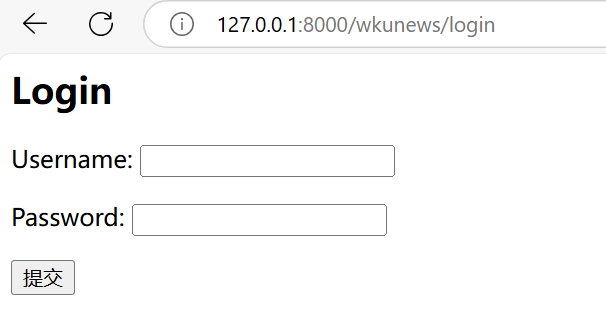

Input the username and password, if the username and password are both 'admin', then system will redirect to the http://127.0.0.1:8000/wkunews/success, otherwise redirect to the login page again.

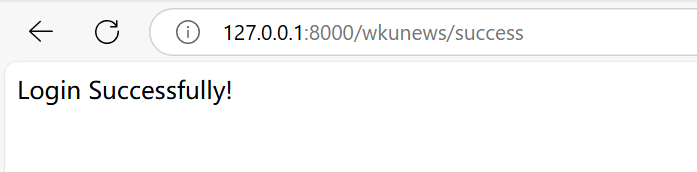

## 3.4 News List

Now, lets revise the view of "success". Instead of displaying the "Login Successfully" message. We show a list of news once the user is successfully logged in.

Modify the view of ``success`` in ``wkunews/views.py``.
- In this example, we define the news by ourself for simplicity. Later, the system can connect to database and perform query and use the results as the news list.

In [ ]:
from django.shortcuts import render
from django.http import HttpResponse,HttpResponseRedirect
import datetime
from .forms import LoginForm
# Create your views here.

def index(request):
    today = datetime.datetime.now().date()
    return render(request,"hello.html",{"today":today})

def success(request):
    newslist=[]
    newslist.append('CPS 3962 Quiz finished')
    newslist.append('CPS 3440 Project Released')
    newslist.append('CSP 3962 Quiz Grade Released')
    today = datetime.datetime.now().date()
    return render(request,"success.html",{"newslist":newslist,"date":today})

def login(request):
    if request.method == 'POST':
        username = ''
        passwd = ''
        form = LoginForm(request.POST or None)
        if form.is_valid():
            username = form.cleaned_data.get("username")
            passwd = form.cleaned_data.get("password")
            if username == "admin" and passwd == "admin":
                return HttpResponseRedirect("success")
            else:
                return HttpResponseRedirect("login")
    else:
        form = LoginForm()
    return render(request, 'login.html', {'form':form})

Add a template ``success.html`` to the folder ``template``:

In [ ]:
<!DOCTYPE html>

<head>
    <title>WKU News</title>
    <style>
        .container {
            margin-top: 30px;
        }

        .row {
            margin-top: 10px;
            margin-bottom: 10px;
        }
    </style>
</head>

<body>
    <div class="container">
        <div class="row">
            <h1>WKU News</h1>
        </div>
        <div class="row">
            <div>Today is {{ date }}</div>
                <ol>
                    {% for news in newslist %}
                        <li>{{ news }}</li>
                    {% endfor %}
                </ol>
            </div>
        </div>
    </div>
</body>

The template is defined using DTL (Django Template Language). You can observe there is a mix of HTML and some variables (``{{ var }}``) and flow control statements (``{% for variable in list%}`` ``{% endfor %}``).
- Refer to the official document of [The Django template language](https://docs.djangoproject.com/en/3.0/ref/templates/language/) for details.

Now, refresh your broswer for the url http://127.0.0.1:8000/wkunews/success, you'll get the news list.

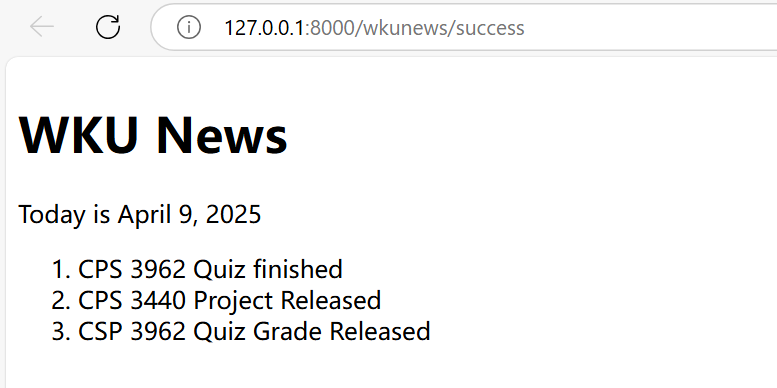